# Projet Python
## Calcul scientifique: Optimisation et classification de données

Choisissez un problème de classification binaire :

- `main-pied` : `hand` vs `foot` ;
- `pingouin-perroquet` : `penguin` vs `parrot` ;
- `oignon-ananas` : `onion` vs `pineapple`.

La première classe porte l'étiquette $0$, la seconde l'étiquette $1$.

L'objectif est de programmer vous-mêmes une régression logistique, son gradient, une descente à pas fixe puis une recherche linéaire d'Armijo. `scikit-learn` ne sera utilisé comme classifieur qu'à la fin, pour comparaison.

Les données proviennent du **Quick, Draw! Dataset** de Google Creative Lab (licence CC BY 4.0). Les fonctions de téléchargement sont fournies.



In [2]:
import json
import time
import urllib.parse
import urllib.request
from pathlib import Path
import importlib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

%matplotlib inline

import dessin_process
importlib.reload(dessin_process)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

### 1. Question préambule:
Commencez par classer intuitivement les trois couples du plus facile au plus difficile pour un humain. Vous reviendrez sur cette réponse à la fin du projet.

### 2.1 Choix du couple
choisissez l'un des couples via la variable $\texttt{PAIR}$. Chargez un nombre identique de dessins $\texttt{N\_PER\_CLASS}$ pour chaque classe. Puis créez un dictionnaire python via la variable $\texttt{PAIRS}$. Un dictionnaire permet d'associer à des clés des valeurs. Dans notre cas: Clé = "main-pied", "pingouin-perroquet" et "oignon-ananas". Valeurs =("hand", "foot", "main", "pied"),("penguin", "parrot", "pingouin", "perroquet") et ("onion", "pineapple", "oignon", "ananas").



Une image en niveaux de gris codée sur 8 bits par pixel utilise un octet par pixel. Chaque pixel est représenté par une valeur entière comprise entre 0 et 255. L’image peut alors être manipulée comme un tableau NumPy uint8 à deux dimensions : la première dimension correspond à la hauteur et la seconde à la largeur.

Complétez $\texttt{compute\_centering\_parameters}$ et $\texttt{image\_converter}$ du module $\texttt{dessin\_process}$ ainsi que les fonctions $\texttt{paint\_disk}$ et $\texttt{paint\_segment}$


In [3]:
## 1/ Choisissez votre problème ici

PAIR = "oignon-ananas"  # "main-pied", "pingouin-perroquet", "oignon-ananas"
N_PER_CLASS = 100

PAIRS = {
    "main-pied": ("hand", "foot", "main", "pied"),
    "pingouin-perroquet": ("penguin", "parrot", "pingouin", "perroquet"),
    "oignon-ananas": ("onion", "pineapple", "oignon", "ananas"),
}

cat0, cat1, nom0, nom1 = PAIRS[PAIR]
print(f"Problème choisi : {nom0} (Étiquette 0) / {nom1} (Étiquette 1)")


Problème choisi : oignon (Étiquette 0) / ananas (Étiquette 1)


#### Fonction $\texttt{paint\_disk}$

Le point `(x, y)` représente le centre du disque, avec `x` correspondant à la colonne et `y` à la ligne. Le disque est de rayon `radius`.
Un pixel de coordonnées `(i, j)` appartient au disque si


$(i-y)^2+(j-x)^2 \leq \texttt{radius}^2.$

Les pixels appartenant au disque devront recevoir la valeur `1` (=blanc).

#### Fonction $\texttt{paint\_segment}$

Les positions successives de la souris peuvent être relativement éloignées lorsque l'utilisateur dessine rapidement. Dessiner uniquement un disque à chaque position provoquerait alors des trous dans le trait.

Complétez la fonction ``` paint_segment(bitmap, p0, p1, radius)```

qui relie deux points $p_0=(x_0,y_0)
\quad\text{et}\quad
p_1=(x_1,y_1)$ par un trait continu.

Pour cela :

1. calculez la distance entre `p0` et `p1` ;
2. choisissez un nombre suffisant de points intermédiaires entre ces deux positions ;
3. utilisez `np.linspace` pour interpoler leurs coordonnées ;
4. appelez `paint_disk` en chacun de ces points.

Attention: Le pas entre deux centres successifs doit être suffisamment petit par rapport au rayon du pinceau pour que les disques se chevauchent et forment un trait continu.


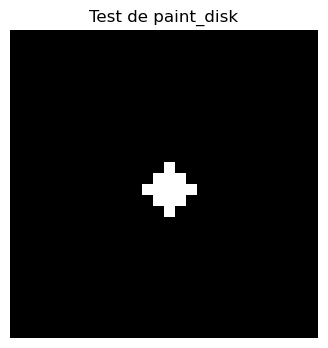

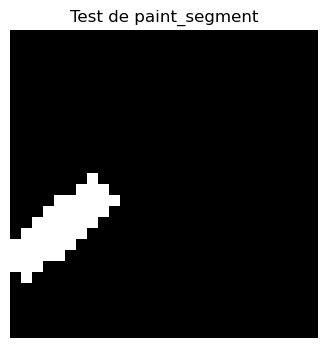

In [4]:
dessin_process.test_paint_disk()
dessin_process.test_paint_segment()

In [5]:
# =================================================================
# TÉLÉCHARGEMENT ET PRÉPARATION DES DONNÉES QUICKDRAW 
# =================================================================
#
# Les traitements d'image sont dans dessin_process.py :
#   - compute_centering_parameters(...)
#   - paint_disk(...)
#   - paint_segment(...)
#   - image_converter(...)
#

BASE_URL = "https://storage.googleapis.com/quickdraw_dataset/full/simplified/"
CACHE_DIR = Path("quickdraw_cache")
CACHE_DIR.mkdir(exist_ok=True)


def load_quickdraw_category(category, n_samples=1200, force=False):
    """Charge ``n_samples`` dessins QuickDraw d'une catégorie.

    Les dessins vectoriels lus dans le fichier NDJSON sont convertis en
    bitmaps 28 x 28 par ``dessin_process.image_converter`` puis mis en cache.
    """
    cache = CACHE_DIR / f"{category}_{n_samples}.npy"

    if cache.exists() and not force:
        return np.load(cache)

    url = BASE_URL + urllib.parse.quote(category) + ".ndjson"
    print(f"Téléchargement d'un sous-ensemble de '{category}'...")

    images = []

    try:
        with urllib.request.urlopen(url, timeout=60) as response:
            for line in response:
                record = json.loads(line.decode("utf-8"))

                # Conversion vectoriel -> bitmap assurée par dessin_process.py.
                images.append(dessin_process.image_converter(record["drawing"]))

                if len(images) >= n_samples:
                    break

    except Exception as exc:
        raise RuntimeError(
            "Impossible de télécharger QuickDraw. Vérifiez la connexion internet. "
            "Une fois les fichiers mis en cache, les séances suivantes peuvent "
            "être faites hors ligne."
        ) from exc

    arr = np.stack(images)
    np.save(cache, arr)
    return arr


def load_pair(pair=PAIR, n_per_class=N_PER_CLASS):
    """Charge les deux catégories correspondant au problème choisi."""
    c0, c1, n0, n1 = PAIRS[pair]

    A = load_quickdraw_category(c0, n_per_class)
    B = load_quickdraw_category(c1, n_per_class)

    Ximg = np.concatenate([A, B], axis=0)
    y = np.concatenate([
        np.zeros(len(A), dtype=int),
        np.ones(len(B), dtype=int)
    ])

    local_rng = np.random.default_rng(RANDOM_STATE)
    idx = local_rng.permutation(len(y))
    return Ximg[idx], y[idx], (n0, n1)

### 2.1 Choix du couple et chargement

Chargez les données.


In [6]:
# 加载两类图片和标签。
Ximg, y, class_names = load_pair()
print("Images :", Ximg.shape)
print("Etiquettes :", y.shape)
print("Effectifs :", np.bincount(y))
print("Classes :", class_names)

Images : (200, 28, 28)
Etiquettes : (200,)
Effectifs : [100 100]
Classes : ('oignon', 'ananas')


### 2.2 Premières visualisations
Affichez au moins 16 dessins de chaque classe à l'aide de matplotlib

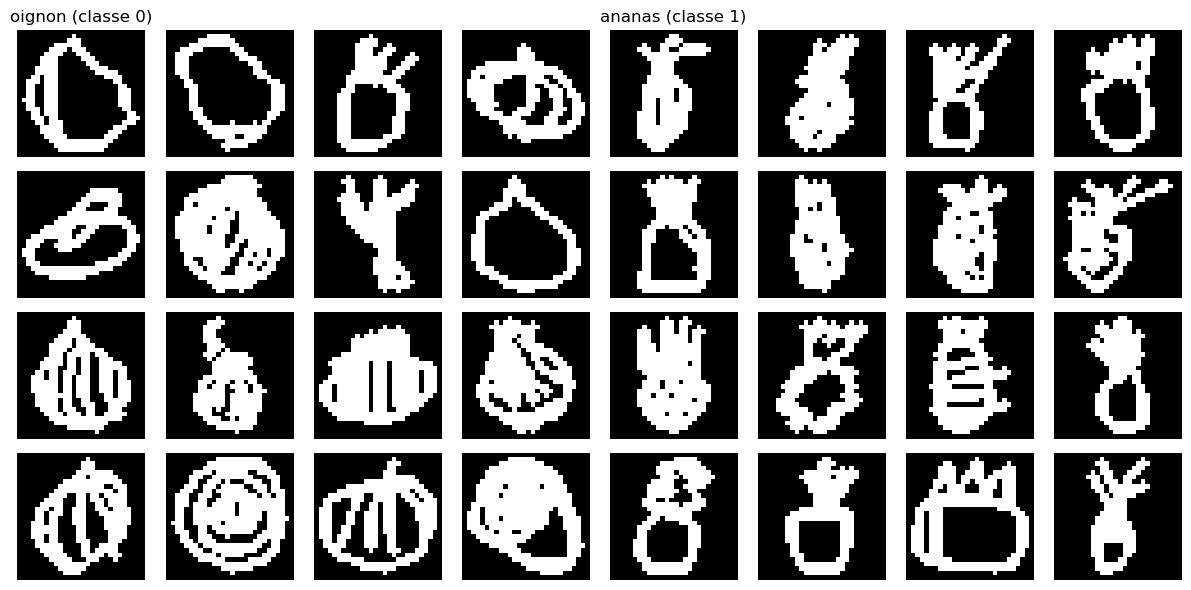

In [ ]:
fig, axes = plt.subplots(4, 8, figsize=(12, 6))

for label in (0, 1):
    indices = np.where(y == label)[0]

    if len(indices) < 16:
        raise ValueError(f"标签 {label} 的图片不足 16 张")

    for i, idx in enumerate(indices[:16]):
        row = i // 4
        col = (i % 4) + label * 4

        axes[row, col].imshow(Ximg[idx], cmap="gray", vmin=0, vmax=255)
        axes[row, col].axis("off")

axes[0, 0].set_title(f"{class_names[0]} (classe 0)")
axes[0, 4].set_title(f"{class_names[1]} (classe 1)")

plt.tight_layout()
plt.show()

### 2.3 Images moyennes

Calculez $\bar x_0$, $\bar x_1$ et $\bar x_1-\bar x_0$. Commentez les zones qui différencient les classes.


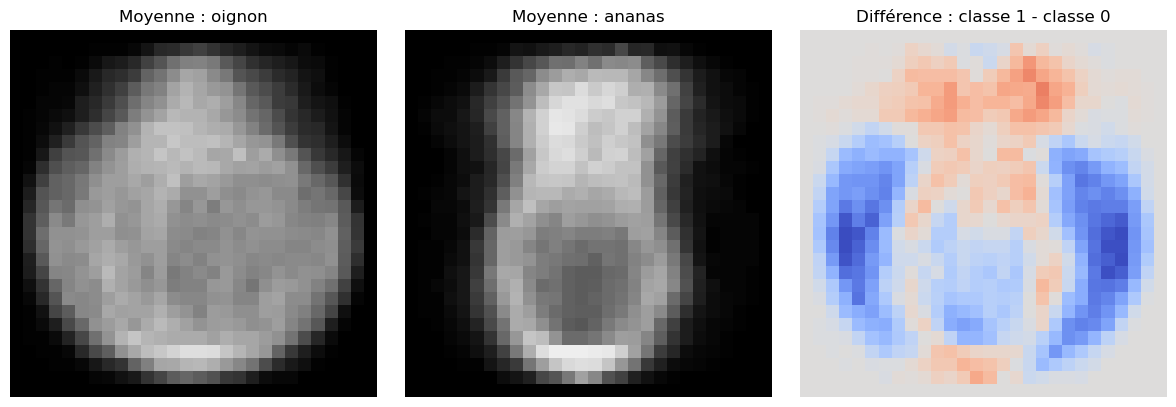

In [8]:
mean_0 = Ximg[y == 0].mean(axis=0)
mean_1 = Ximg[y == 1].mean(axis=0)
difference = mean_1 - mean_0

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(mean_0, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"Moyenne : {class_names[0]}")

axes[1].imshow(mean_1, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"Moyenne : {class_names[1]}")

limit = np.abs(difference).max()
axes[2].imshow(difference, cmap="coolwarm", vmin=-limit, vmax=limit)
axes[2].set_title("Différence : classe 1 - classe 0")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### 2.4 Prétraitement et séparation apprentissage/test

Normalisez les pixels dans $[0,1]$, aplatissez chaque image en un vecteur de dimension 784 puis conservez 70 % des données pour l'apprentissage et 30 % pour le test.



In [ ]:
from sklearn.model_selection import train_test_split

X = Ximg.astype(float) / 255.0

X = X.reshape(X.shape[0], -1)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("ensemble d'entraînement:", X_train.shape, y_train.shape)
print("ensemble de test:", X_test.shape, y_test.shape)

ensemble d'entraînement: (140, 784) (140,)
ensemble de test: (60, 784) (60,)


## 3. Construire le classifieur! 
On pose
$$
P(y=1\mid x)=\sigma(w^T x+b),\qquad \sigma(z)=\frac{1}{1+e^{-z}}.
$$

On absorbe le biais en ajoutant une colonne de 1 aux données via $\texttt{add\_bias}$.

### 3.1 Score linéaire et sigmoïde
Programmez $\texttt{sigmoid(z)}$ et tracez cette fonction.



In [64]:
def add_bias(X):
    return np.c_[X, np.ones(X.shape[0])]

def sigmoid(z):
    z = np.asarray(z, dtype=float)
    return 1 / (1 + np.exp(-z))


X_train_b = add_bias(X_train)
X_test_b = add_bias(X_test)

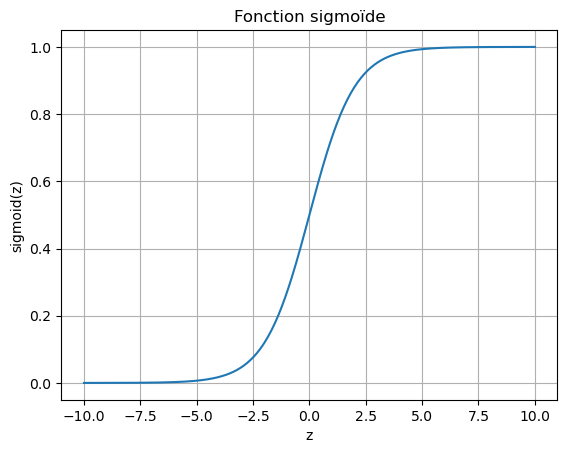

In [65]:
plt.close("all")
z = np.linspace(-10, 10, 400)
plt.plot(z, sigmoid(z))
plt.xlabel("z")
plt.ylabel("sigmoid(z)")
plt.title("Fonction sigmoïde")
plt.grid(True)
plt.show()

### 3.2 Log-loss régularisée
Complétez le code.
    
$$
f(\theta)=-\frac1n\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)]
+\frac{\lambda}{2}\|w\|^2.
$$

Le biais n'est pas régularisé.

**Questions.** Quelle contribution donne une observation de classe $1$ lorsque le modèle prédit $p_i=0.99$ ? Et lorsque le modèle prédit $p_i=0.01$ ? Comparez qualitativement.

**Question.** Pourquoi la log-loss pénalise-t-elle fortement une prédiction très confiante mais fausse ?

**Question.** Quel est le rôle de $\lambda$ ? Que devrait devenir la norme de $w$ lorsque $\lambda$ augmente ?

**Question.** Pourquoi choisit-on ici de ne pas régulariser le biais $b$ ?

### 3.3 Gradient
On veut montrer que, sans régularisation,
$$
\nabla f(\theta)=\frac1n\widetilde X^\top(p-y), 
$$
et avec régularisation,
$$
\nabla f(\theta)=\frac1n\widetilde X^\top(p-y)
+\lambda\begin{pmatrix}w\\0\end{pmatrix}.
$$

**Exercice.** Retrouvez les formules ci-dessus en utilisant $\sigma'(z)=\sigma(z)(1-\sigma(z))$.

Vérifiez soigneusement les dimensions de toutes les quantités dans l'expression matricielle du gradient.
Complétez le code ci-dessous.


In [66]:
def objective(theta, Xb, y, lmbda=1e-2):
    p = sigmoid(Xb @ theta)
    eps = 1e-15
    p = np.clip(p, eps, 1 - eps)

    data_loss = np.mean(
        -y * np.log(p) - (1 - y) * np.log(1 - p)
    )

    w = theta[:-1]  
    regularization = lmbda / 2 * np.sum(w ** 2)

    return data_loss + regularization


def grad_objective(theta, Xb, y, lmbda=1e-2):
    p = sigmoid(Xb @ theta)
    grad = Xb.T @ (p - y) / len(y)
    grad[:-1] += lmbda * theta[:-1]
    return grad

1. Contribution d'une observation de classe 1
Pour une observation dont la vraie classe est 
y
i
=
1
y 
i
​
 =1, sa contribution à la log-loss est :

−
log
⁡
(
p
i
)
−log(p 
i
​
 )
Si 
p
i
=
0,99
p 
i
​
 =0,99, la contribution vaut 
−
log
⁡
(
0,99
)
≈
0,010
−log(0,99)≈0,010. Elle est faible : le modèle attribue une forte probabilité à la vraie classe.
Si 
p
i
=
0,01
p 
i
​
 =0,01, elle vaut 
−
log
⁡
(
0,01
)
≈
4,605
−log(0,01)≈4,605. Elle est beaucoup plus élevée : le modèle attribue une très faible probabilité à la vraie classe.


### 3.4 Vérification par différences finies

Comparez votre gradient à une approximation par différences centrées. Testez plusieurs valeurs de $h$ et commentez l'effet des erreurs d'arrondi.



In [72]:
def finite_difference_gradient(f, theta, h=1e-6, indices=None):
    
    if indices is None:
        indices = np.arange(theta.size)
    g = np.full(theta.shape, np.nan, dtype=float)
    for j in indices:
        e = np.zeros_like(theta, dtype=float)
        e[j] = 1.0
        g[j] = (f(theta + h*e) - f(theta - h*e)) / (2*h)
    return g

check_rng = np.random.default_rng(RANDOM_STATE)
theta_check = check_rng.normal(0, 0.05, X_train_b.shape[1])

f = lambda theta: objective(
    theta, X_train_b, y_train, lmbda=1e-2
)

indices = np.array([0, 1, 100, theta_check.size - 1]) 
grad_exact = grad_objective(theta_check, X_train_b, y_train, lmbda=1e-2)

for h in [1e-2, 1e-4, 1e-6]:
    grad_num = finite_difference_gradient(f, theta_check, h=h, indices=indices)
    errors = np.abs(grad_num[indices] - grad_exact[indices])

    print(f"h={h:g}, erreur absolue maximale={errors.max():.3e}")

    assert errors.max() < 1e-4, "La vérification du gradient a échoué."

h=0.01, erreur absolue maximale=1.105e-06
h=0.0001, erreur absolue maximale=1.108e-10
h=1e-06, erreur absolue maximale=6.057e-11


### 4. Optimiser la log-loss !!
#### Descente de gradient à pas fixe

On souhaite maintenant implémenter une descente de gradient à pas fixe: 
$$
\theta_{k+1}=\theta_k-\alpha\nabla f(\theta_k).
$$


Programmez une fonction $\texttt{gradient\_descent\_fixed}$ retournant: la solution, les valeurs de $f$, les normes du gradient et le nombre d'itérations.

Testez plusieurs pas et tracez $f(\theta_k)$ ainsi que $\|\nabla f(\theta_k)\|$.

In [ ]:
def gradient_descent_fixed(f, gradf, theta0, alpha,
                           tol=1e-5, max_iter=1000):
    start = time.process_time()
    theta = np.array(theta0, dtype=float).copy()
    list_f = [f(theta)]
    grad = gradf(theta)
    list_g = [np.linalg.norm(grad)]

    for k in range(max_iter):
        if list_g[-1] <= tol:
            break
        theta = theta - alpha * grad
        list_f.append(f(theta))
        grad = gradf(theta)
        list_g.append(np.linalg.norm(grad))
        if not np.isfinite(list_f[-1]) or not np.isfinite(list_g[-1]):
            break

    iterations = len(list_f) - 1
    return {
        "theta": theta, "f": np.array(list_f),
        "grad_norm": np.array(list_g),
        "alpha": np.full(iterations, alpha),
        "iterations": iterations, "n_f_eval": len(list_f),
        "time": time.process_time() - start,
    }

Tracez
    
$$
k\mapsto f(\theta_k),
\qquad
k\mapsto\|\nabla f(\theta_k)\|.
$$

Testez plusieurs valeurs de $\alpha$ sur le même point initial, par exemple $10^{-3}$, $10^{-2}$, $10^{-1}$, $0.5$, $1$, et $5$.


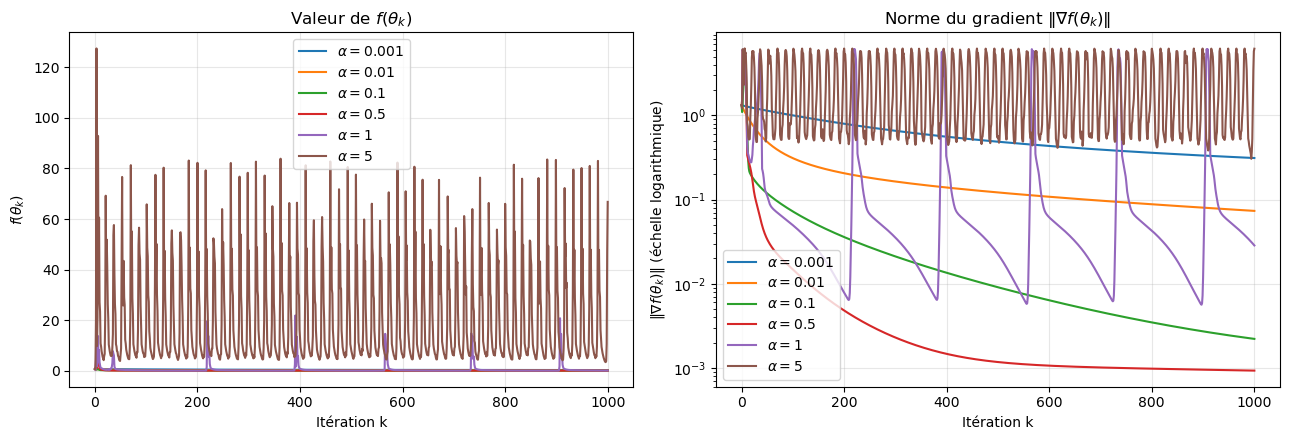

alpha=0.001 : 1000 itérations, f final=0.291391, ||grad f|| final=3.115e-01
alpha=0.01 : 1000 itérations, f final=0.110577, ||grad f|| final=7.341e-02
alpha=0.1 : 1000 itérations, f final=0.0694433, ||grad f|| final=2.217e-03
alpha=0.5 : 1000 itérations, f final=0.0689623, ||grad f|| final=9.310e-04
alpha=1 : 1000 itérations, f final=0.088842, ||grad f|| final=2.853e-02
alpha=5 : 1000 itérations, f final=66.779, ||grad f|| final=6.188e+00


In [69]:
import numpy as np
import matplotlib.pyplot as plt

lmbda = 1e-2
f_train = lambda theta: objective(theta, X_train_b, y_train, lmbda=lmbda)
g_train = lambda theta: grad_objective(theta, X_train_b, y_train, lmbda=lmbda)

# Même point initial pour tous les pas
theta0 = np.zeros(X_train_b.shape[1])
alphas = [1e-3, 1e-2, 1e-1, 0.5, 1, 5]
fixed_results = {}

for alpha in alphas:
    fixed_results[alpha] = gradient_descent_fixed(
        f_train, g_train, theta0, alpha=alpha,
        tol=1e-5, max_iter=1000,
    )
fixed_step_results = fixed_results.copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for alpha, result in fixed_results.items():
    k_f = np.arange(len(result["f"]))
    k_g = np.arange(len(result["grad_norm"]))
    axes[0].plot(k_f, result["f"], label=fr"$\alpha={alpha:g}$")
    axes[1].semilogy(
        k_g,
        np.maximum(result["grad_norm"], np.finfo(float).tiny),
        label=fr"$\alpha={alpha:g}$",
    )

axes[0].set_title(r"Valeur de $f(\theta_k)$")
axes[0].set_xlabel("Itération k")
axes[0].set_ylabel(r"$f(\theta_k)$")
axes[1].set_title(r"Norme du gradient $\|\nabla f(\theta_k)\|$")
axes[1].set_xlabel("Itération k")
axes[1].set_ylabel(r"$\|\nabla f(\theta_k)\|$ (échelle logarithmique)")

for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.tight_layout()
plt.show()

for alpha, result in fixed_results.items():
    print(
        f"alpha={alpha:g} : {result['iterations']} itérations, "
        f"f final={result['f'][-1]:.6g}, "
        f"||grad f|| final={result['grad_norm'][-1]:.3e}"
    )

### 4.2 BONUS Règle d'Armijo

Pour $d_k=-\nabla f(\theta_k)$, on cherche $\alpha>0$ tel que
$$
f(\theta_k+\alpha d_k)
\leq
f(\theta_k)+c_1\alpha\nabla f(\theta_k)^\top d_k.
$$
Un backtracking part de $\alpha_0$ et remplace
$$
\alpha\leftarrow\rho\alpha,
\qquad 0<\rho<1,
$$
tant que la condition n'est pas satisfaite.

Programmez $\texttt{armijo\_step}$ puis une descente de gradient utilisant ce pas.



In [ ]:
def armijo_step(f, gradf, theta, d,
                alpha0=1.0, rho=0.5, c1=1e-4,
                min_alpha=1e-12, f0=None, g0=None):
    if not (alpha0 > 0 and min_alpha > 0 and 0 < rho < 1 and 0 < c1 < 1):
        raise ValueError("需要正步长，并且 0 < rho, c1 < 1。")
    n_eval = 0
    if f0 is None:
        f0 = f(theta)
        n_eval += 1
    if g0 is None:
        g0 = gradf(theta)

    alpha = alpha0
    slope = np.dot(g0, d)
    # 不满足下降要求，就把步长乘以 rho 缩小。
    while alpha >= min_alpha:
        new_f = f(theta + alpha * d)
        n_eval += 1
        if np.isfinite(new_f) and new_f <= f0 + c1 * alpha * slope:
            return alpha, n_eval
        alpha = alpha * rho
    raise RuntimeError("Armijo 没找到合适步长，请检查梯度或参数。")


def gradient_descent_armijo(f, gradf, theta0,
                            tol=1e-5, max_iter=1000,
                            alpha0=1.0, rho=0.5, c1=1e-4):
    start = time.process_time()
    theta = np.array(theta0, dtype=float).copy()
    hist_f = [f(theta)]
    grad = gradf(theta)
    hist_g = [np.linalg.norm(grad)]
    hist_a = []
    n_f_eval = 1

    for k in range(max_iter):
        if hist_g[-1] <= tol:
            break
        d = -grad
        alpha, n_eval = armijo_step(
            f, gradf, theta, d, alpha0, rho, c1,
            f0=hist_f[-1], g0=grad,
        )
        theta = theta + alpha * d
        hist_a.append(alpha)
        # 搜索过程中计算的每次 f，以及这里这次 f，都计入次数。
        n_f_eval += n_eval
        hist_f.append(f(theta))
        n_f_eval += 1
        grad = gradf(theta)
        hist_g.append(np.linalg.norm(grad))

    return {
        "theta": theta, "f": np.array(hist_f),
        "grad_norm": np.array(hist_g), "alpha": np.array(hist_a),
        "iterations": len(hist_a), "n_f_eval": n_f_eval,
        "time": time.process_time() - start,
    }

### 4.3 BONUS Comparaison numérique
Comparez pas fixe et Armijo selon :
- nombre d'itérations ;
- nombre d'évaluations de $f$ ;
- temps CPU ;
- valeur finale de $f$ ;
- norme finale du gradient.


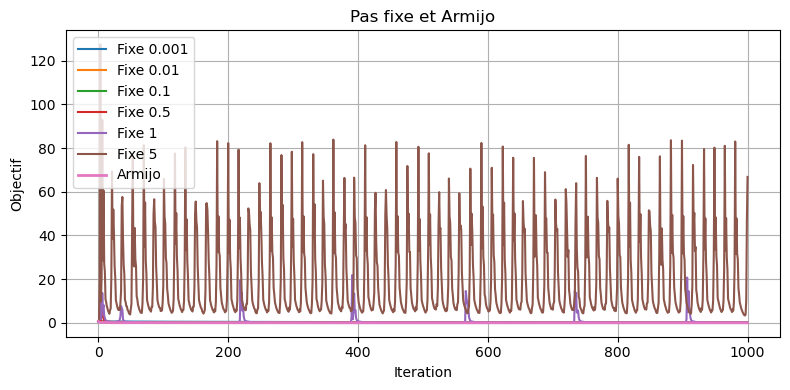

Methode         Iter.  Eval. f     CPU(s)     f final   Norme grad.
Fixe 0.001       1000     1001     0.1101    0.291391     3.115e-01
Fixe 0.01        1000     1001     0.1085    0.110577     7.341e-02
Fixe 0.1         1000     1001     0.1089    0.069443     2.217e-03
Fixe 0.5         1000     1001     0.1085    0.068962     9.310e-04
Fixe 1           1000     1001     0.1091    0.088842     2.853e-02
Fixe 5           1000     1001     0.1081   66.778969     6.188e+00
Armijo           1000     2794     0.1881    0.068843     1.493e-03
Temps CPU mesure avec process_time ; il depend de la machine.


In [ ]:
# 复用 4.1 的固定步长结果，不覆盖或重复训练它们。
# 两种方法使用相同初始点、目标函数、容差和迭代上限。
armijo_result = gradient_descent_armijo(
    f_train, g_train, theta0, tol=1e-5, max_iter=1000
)

fig, ax = plt.subplots(figsize=(8, 4))
for alpha, result in fixed_step_results.items():
    ax.plot(result["f"], label=f"Fixe {alpha:g}")
ax.plot(armijo_result["f"], label="Armijo", linewidth=2)
ax.set(xlabel="Iteration", ylabel="Objectif", title="Pas fixe et Armijo")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

comparison_results = {}
for alpha, result in fixed_step_results.items():
    comparison_results[f"Fixe {alpha:g}"] = result
comparison_results["Armijo"] = armijo_result

print(f"{'Methode':<14} {'Iter.':>6} {'Eval. f':>8} {'CPU(s)':>10} {'f final':>11} {'Norme grad.':>13}")
for name, result in comparison_results.items():
    print(f"{name:<14} {result['iterations']:6d} {result['n_f_eval']:8d} "
          f"{result['time']:10.4f} {result['f'][-1]:11.6f} "
          f"{result['grad_norm'][-1]:13.3e}")
print("Temps CPU mesure avec process_time ; il depend de la machine.")

**优化结果的读法**：小固定步长通常下降慢，大步长可能震荡。Armijo 在不满足下降条件时缩短步长，
但要多计算目标函数，所以迭代少不一定运行更快。表中梯度范数达到容差才算本次收敛；达到迭代上限不等于收敛。

**本次观察**：步长 5 明显震荡，不能使用；1000 次迭代内各方法都没有达到 `1e-5` 的梯度容差。
所以下一节从比较中目标值最低的解出发，再运行 Armijo，直到梯度范数约为 `9.89e-6`。
这段追加优化不包含在上面统一 1000 次迭代的比较表中。


## Avant l'évaluation du modèle, on retient le meilleur parametre $\theta^*$

In [18]:
# 比较阶段统一使用 1000 次迭代，便于公平比较。
# 现在只根据训练目标选一个较好的初始解，再增加迭代使其收敛。
# 不用测试集选参数。
finite_results = {}
for name, result in comparison_results.items():
    if np.isfinite(result["f"][-1]) and np.isfinite(result["grad_norm"][-1]):
        finite_results[name] = result
if len(finite_results) == 0:
    raise RuntimeError("所有方法都出现非有限数值，请检查步长。")

best_name = min(finite_results, key=lambda name: finite_results[name]["f"][-1])
best_result = finite_results[best_name]
print("Point de depart retenu :", best_name)

# 没达到容差时继续优化，不能把达到迭代上限叫作收敛。
if best_result["grad_norm"][-1] > 1e-5:
    best_result = gradient_descent_armijo(
        f_train, g_train, best_result["theta"], tol=1e-5, max_iter=20000
    )
    print("Iterations supplementaires (Armijo) :", best_result["iterations"])
if best_result["grad_norm"][-1] > 1e-5:
    raise RuntimeError("增加迭代后仍未达到容差，请检查输出。")

theta_star = best_result["theta"].copy()
print("f(theta_star) =", best_result["f"][-1])
print("Norme du gradient =", best_result["grad_norm"][-1])

Point de depart retenu : Armijo
Iterations supplementaires (Armijo) : 14948
f(theta_star) = 0.06807541361384162
Norme du gradient = 9.893967376394994e-06


## 5. Évaluer et interpréter !!!
Calculez les probabilités et les classes sur le jeu de test, puis l'accuracy, la précision, le rappel et la matrice de confusion.



Accuracy  : 0.833
Précision (classe ananas) : 0.812
Rappel (classe ananas)    : 0.867
Matrice de confusion (lignes = vraies classes, colonnes = prédictions) :
[[24  6]
 [ 4 26]]


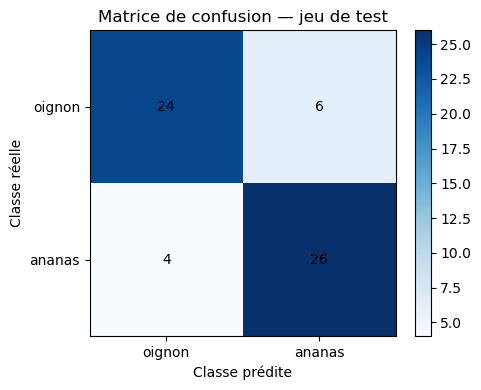

In [19]:
def predict_proba(theta, Xb):
    return sigmoid(Xb @ theta)


def predict(theta, Xb, threshold=0.5):
    if not 0 <= threshold <= 1:
        raise ValueError("threshold doit être compris entre 0 et 1.")
    return (predict_proba(theta, Xb) >= threshold).astype(int)


from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

# Probabilités et classes prédites sur le jeu de test
p_test = predict_proba(theta_star, X_test_b)
y_pred = predict(theta_star, X_test_b, threshold=0.5)

# La classe positive est la classe 1
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
recall = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print(f"Accuracy  : {accuracy:.3f}")
print(f"Précision (classe {class_names[1]}) : {precision:.3f}")
print(f"Rappel (classe {class_names[1]})    : {recall:.3f}")
print("Matrice de confusion (lignes = vraies classes, colonnes = prédictions) :")
print(cm)

fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], labels=class_names)
ax.set_yticks([0, 1], labels=class_names)
ax.set_xlabel("Classe prédite")
ax.set_ylabel("Classe réelle")
ax.set_title("Matrice de confusion — jeu de test")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.colorbar(image, ax=ax)
fig.tight_layout()
plt.show()


### 5.2 Dessins mals classés

Affichez plusieurs dessins mal classés et les dessins dont la probabilité est la plus proche de $0.5$. 

Cherchez aussi un cas où le modèle se trompe avec une forte confiance.


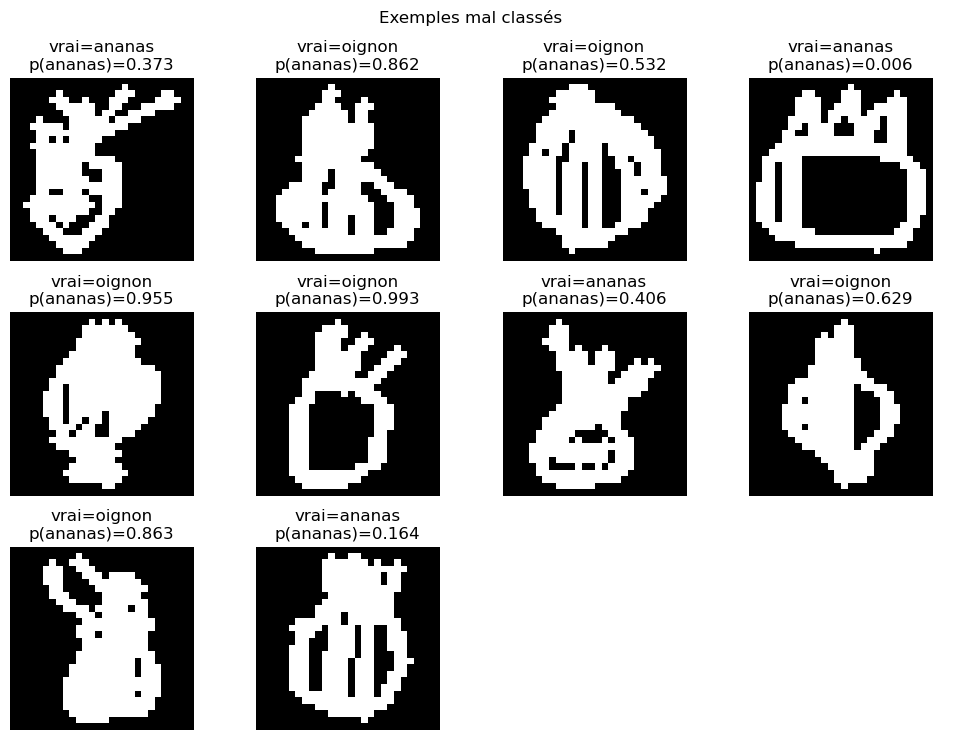

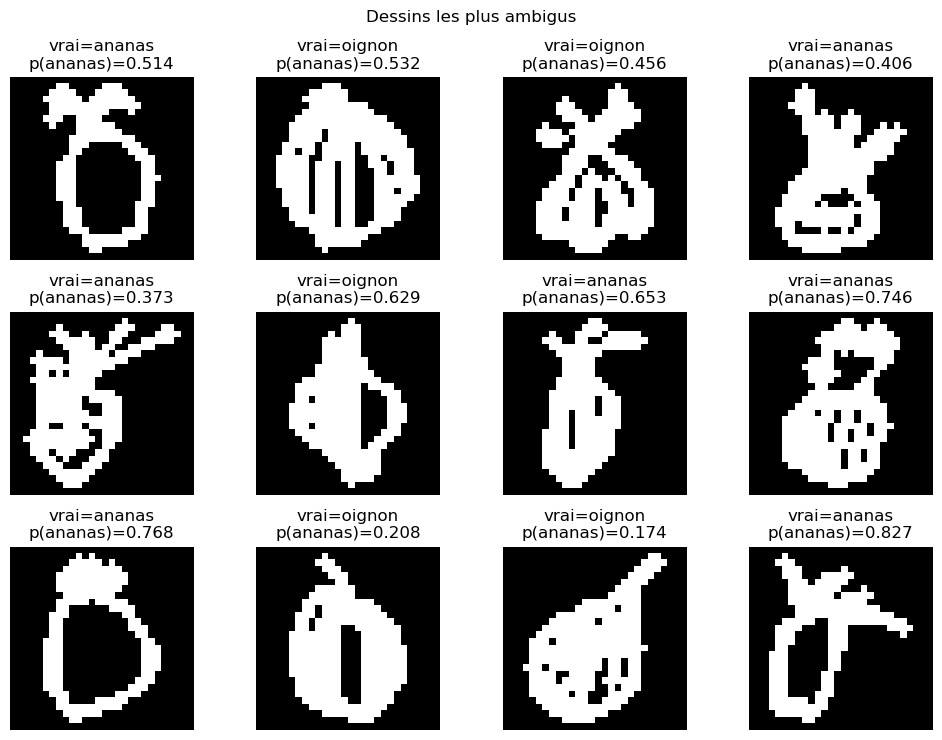

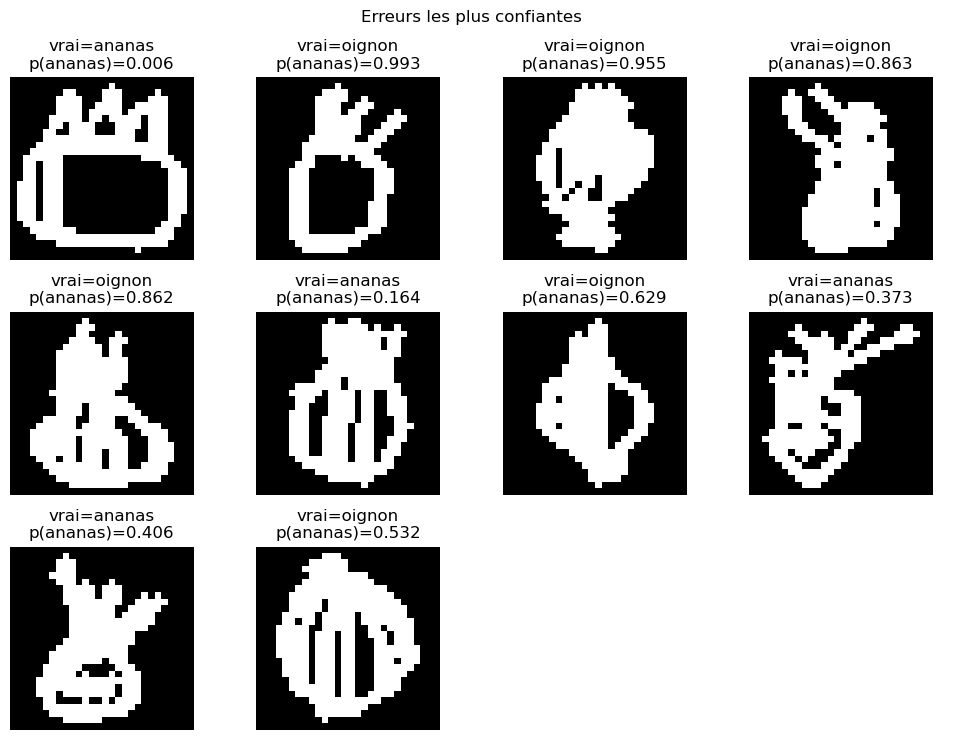

In [20]:
def show_indices(indices, title, max_n=12):
    indices = np.asarray(indices)[:max_n]
    n = len(indices)
    if n == 0:
        print(title, ": aucun exemple")
        return
    cols = 4
    rows = int(np.ceil(n/cols))
    fig, axes = plt.subplots(rows, cols, figsize=(10, 2.5*rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, i in zip(axes, indices):
        ax.imshow(X_test[i].reshape(28,28), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"vrai={class_names[y_test[i]]}\np({class_names[1]})={p_test[i]:.3f}")
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

wrong = np.where(y_pred != y_test)[0]
show_indices(wrong, "Exemples mal classés")

ambiguous = np.argsort(np.abs(p_test - 0.5))
show_indices(ambiguous, "Dessins les plus ambigus")

if len(wrong):
    confident_wrong = wrong[np.argsort(-np.abs(p_test[wrong]-0.5))]
    show_indices(confident_wrong, "Erreurs les plus confiantes")

### 5.3 Visualiser le vecteur $w$
Remettez $w\in\mathbb{R}^{784}$ sous forme d'une image $28\times28$. Les coefficients positifs favorisent la classe 1, les négatifs la classe 0. Comparez cette carte à $\bar x_1-\bar x_0$.


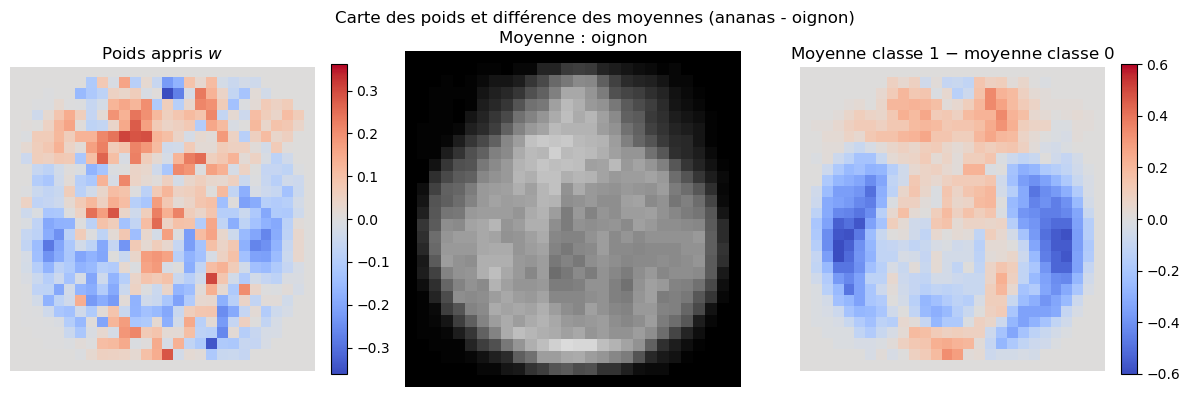

Les poids positifs favorisent la classe ananas
Les poids négatifs favorisent la classe oignon


In [21]:
w = theta_star[:-1]
w_image = w.reshape(28, 28)

mean_class0 = X_train[y_train == 0].mean(axis=0).reshape(28, 28)
mean_class1 = X_train[y_train == 1].mean(axis=0).reshape(28, 28)
mean_difference = mean_class1 - mean_class0

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

weight_limit = np.max(np.abs(w_image))
diff_limit = np.max(np.abs(mean_difference))
im0 = axes[0].imshow(
    w_image, cmap="coolwarm", vmin=-weight_limit, vmax=weight_limit
)
axes[0].set_title(r"Poids appris $w$")
fig.colorbar(im0, ax=axes[0], fraction=0.046)

axes[1].imshow(mean_class0, cmap="gray", vmin=0, vmax=1)
axes[1].set_title(f"Moyenne : {class_names[0]}")

axes[2].imshow(
    mean_difference, cmap="coolwarm", vmin=-diff_limit, vmax=diff_limit
)
axes[2].set_title(r"Moyenne classe 1 $-$ moyenne classe 0")
fig.colorbar(axes[2].images[0], ax=axes[2], fraction=0.046)

for ax in axes:
    ax.axis("off")

fig.suptitle(
    f"Carte des poids et différence des moyennes ({class_names[1]} - {class_names[0]})"
)
fig.tight_layout()
plt.show()

print("Les poids positifs favorisent la classe", class_names[1])
print("Les poids négatifs favorisent la classe", class_names[0])

**权重图与均值差的区别**：均值差只比较每个位置的平均像素；权重是优化分类损失后得到的系数，
会同时考虑其他像素和正则化的影响，因此两张图可能相似，但不会完全相同。不能仅根据某个像素权重推断因果关系。

### 5.4 Comparaison à sklearn

utilisez `LogisticRegression` comme référence et comparez les performances. Les conventions de régularisation peuvent différer.


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

# objective() utilise la log-loss moyenne + lmbda/2 * ||w||^2.
# sklearn utilise la log-loss sommée + 1/(2*C) * ||w||^2.
# C = 1/(n*lmbda) aligne donc les coefficients de régularisation.
C_equivalent = 1 / (len(y_train) * lmbda)

sk_model = LogisticRegression(
    C=C_equivalent,
    penalty="l2",
    solver="lbfgs",
    max_iter=5000,
    random_state=RANDOM_STATE,
)
sk_model.fit(X_train, y_train)

y_pred_sklearn = sk_model.predict(X_test)
p_test_sklearn = sk_model.predict_proba(X_test)[:, 1]

accuracy_sklearn = accuracy_score(y_test, y_pred_sklearn)
precision_sklearn = precision_score(
    y_test, y_pred_sklearn, pos_label=1, zero_division=0
)
recall_sklearn = recall_score(
    y_test, y_pred_sklearn, pos_label=1, zero_division=0
)
cm_sklearn = confusion_matrix(y_test, y_pred_sklearn, labels=[0, 1])

print(f"Paramètre C utilisé : {C_equivalent:.6g}")
print("\nComparaison des performances sur le jeu de test")
print(f"{'Modèle':<18} {'Accuracy':>10} {'Précision':>10} {'Rappel':>10}")
print(f"{'Implémentation':<18} {accuracy:>10.3f} {precision:>10.3f} {recall:>10.3f}")
print(f"{'scikit-learn':<18} {accuracy_sklearn:>10.3f} {precision_sklearn:>10.3f} {recall_sklearn:>10.3f}")
print("\nMatrice de confusion scikit-learn (lignes = vraies classes, colonnes = prédictions) :")
print(cm_sklearn)

print(
    "\nTaux de prédictions identiques entre les deux modèles : "
    f"{np.mean(y_pred == y_pred_sklearn):.3f}"
)
print(
"Écart absolu moyen entre les probabilités des deux modèles : "
    f"{np.mean(np.abs(p_test - p_test_sklearn)):.3f}"
)

Paramètre C utilisé : 0.714286

Comparaison des performances sur le jeu de test
Modèle               Accuracy  Précision     Rappel
Implémentation          0.833      0.812      0.867
scikit-learn            0.833      0.812      0.867

Matrice de confusion scikit-learn (lignes = vraies classes, colonnes = prédictions) :
[[24  6]
 [ 4 26]]

Taux de prédictions identiques entre les deux modèles : 1.000
Écart absolu moyen entre les probabilités des deux modèles : 0.001


### 5.5 Bonus — 一个含 3 个神经元的隐藏层

参考 CJJ 的思路，结构为 **784 → 3 → 1**：先从 784 个像素算出 3 个隐藏值，再算出一个分类概率。

$$H=\sigma(XW_1+b_1),\qquad p=\sigma(HW_2+b_2).$$

`W1` 的形状是 `(784, 3)`，`b1` 是 `(3,)`；`W2` 是 `(3,)`，`b2` 是一个数。
输出层只有一个神经元，所以这里直接用一维数组表示 `W2`，方便阅读。
隐藏层也需要 sigmoid，否则两层仿射变换可以合并，分类边界仍是直线/超平面。
本节不做多层封装，也不搜索超参数，训练和测试划分与前面完全相同。

In [23]:
def initialize_nn(n_features, n_hidden=3, seed=42):
    local_rng = np.random.default_rng(seed)
    # Xavier 初始化：随机权重的范围由输入、输出个数决定。
    limit1 = np.sqrt(6 / (n_features + n_hidden))
    limit2 = np.sqrt(6 / (n_hidden + 1))
    W1 = local_rng.uniform(-limit1, limit1, (n_features, n_hidden))
    b1 = np.zeros(n_hidden)
    W2 = local_rng.uniform(-limit2, limit2, n_hidden)
    b2 = 0.0
    return W1, b1, W2, b2


def forward_nn(X, W1, b1, W2, b2):
    H = sigmoid(X @ W1 + b1)   # 每张图片得到 3 个隐藏值
    scores = H @ W2 + b2       # 每张图片得到 1 个分数
    p = sigmoid(scores)        # 分数转换成概率
    return H, scores, p


def objective_nn(X, y, W1, b1, W2, b2, lmbda_nn):
    H, scores, p = forward_nn(X, W1, b1, W2, b2)
    loss = np.mean(np.logaddexp(0, scores) - y * scores)
    # 和前面一样，只正则化权重，不正则化偏置。
    penalty = lmbda_nn / 2 * (np.sum(W1 ** 2) + np.sum(W2 ** 2))
    return loss + penalty


def gradient_nn(X, y, W1, b1, W2, b2, lmbda_nn):
    H, scores, p = forward_nn(X, W1, b1, W2, b2)
    n = len(y)
    # 第一步：输出层的误差和梯度。
    error_out = p - y                    # 形状 (n,)
    dW2 = H.T @ error_out / n + lmbda_nn * W2
    db2 = np.mean(error_out)
    # 第二步：将误差传回隐藏层，乘 sigmoid 的导数 H*(1-H)。
    # [:, None] 将 (n,) 变为 (n,1)，才能与 3 个输出权重相乘。
    error_hidden = error_out[:, None] * W2 * H * (1 - H)
    dW1 = X.T @ error_hidden / n + lmbda_nn * W1
    db1 = np.mean(error_hidden, axis=0)
    return dW1, db1, dW2, db2


def train_nn(X, y, lmbda_nn, eta=0.1, max_iter=2000):
    W1, b1, W2, b2 = initialize_nn(X.shape[1], seed=RANDOM_STATE)
    history = [objective_nn(X, y, W1, b1, W2, b2, lmbda_nn)]
    for k in range(max_iter):
        # 所有梯度都先用旧参数计算完，再一起更新。
        dW1, db1, dW2, db2 = gradient_nn(X, y, W1, b1, W2, b2, lmbda_nn)
        W1 = W1 - eta * dW1
        b1 = b1 - eta * db1
        W2 = W2 - eta * dW2
        b2 = b2 - eta * db2
        history.append(objective_nn(X, y, W1, b1, W2, b2, lmbda_nn))
    return W1, b1, W2, b2, np.array(history)

#### 检查反向传播

先用训练集的一小部分检查梯度。每次只改一个参数，比较损失的变化与手写梯度。
检查包括两层的权重和偏置，也包括正则项；误差应很小。

In [24]:
# 用较小输入检查全部参数，避免对 784*3 个权重逐个做差分。
# 这里只验证公式，下面正式训练仍然使用全部 784 个像素。
# 人工小数组只用于验证公式，不参与正式训练或性能评估。
# 使用非零输入，避免边缘的空白像素让权重梯度全为零。
check_rng_nn = np.random.default_rng(RANDOM_STATE)
X_check_nn = check_rng_nn.random((8, 5))
y_check_nn = np.array([0, 1, 0, 1, 0, 1, 0, 1])
check_params = list(initialize_nn(5, seed=RANDOM_STATE))
check_lambda_nn = 0.1
check_grads = gradient_nn(X_check_nn, y_check_nn, *check_params, check_lambda_nn)
h_nn = 1e-5
max_error_nn = 0.0

# *check_params 的意思是把列表里的 4 项依次传给函数。
# np.ndindex 会依次给出数组中的位置，例如 (0,0)、(0,1)。
# 下面只是在小数组中逐个参数做中心差分，不参与模型训练。
for layer_param in range(4):  # W1、b1、W2、b2
    parameter = np.asarray(check_params[layer_param])
    for index in np.ndindex(parameter.shape):
        plus = [np.array(value, copy=True) for value in check_params]
        minus = [np.array(value, copy=True) for value in check_params]
        plus[layer_param][index] += h_nn
        minus[layer_param][index] -= h_nn
        loss_plus = objective_nn(X_check_nn, y_check_nn, *plus, check_lambda_nn)
        loss_minus = objective_nn(X_check_nn, y_check_nn, *minus, check_lambda_nn)
        numeric = (loss_plus - loss_minus) / (2 * h_nn)
        exact = np.asarray(check_grads[layer_param])[index]
        max_error_nn = max(max_error_nn, abs(numeric - exact))

print(f"Erreur maximale du gradient NN : {max_error_nn:.3e}")
assert max_error_nn < 1e-6

Erreur maximale du gradient NN : 1.613e-11


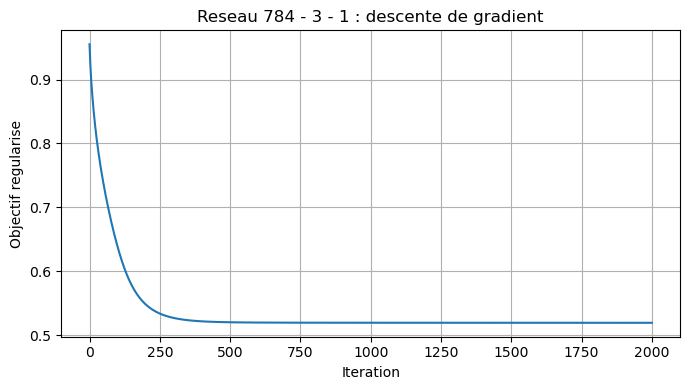

Modele                 Loss train   Loss test   Accuracy  Precision   Rappel
Logistique GD              0.0283      0.4422      0.833      0.812    0.867
  Matrice de confusion : [[24, 6], [4, 26]]
Logistique sklearn         0.0283      0.4425      0.833      0.812    0.867
  Matrice de confusion : [[24, 6], [4, 26]]
NN GD                      0.3349      0.4239      0.850      0.818    0.900
  Matrice de confusion : [[24, 6], [3, 27]]
NN Adam                    0.4127      0.4734      0.850      0.839    0.867
  Matrice de confusion : [[25, 5], [4, 26]]
Loss NN GD : 0.9553864702423592 -> 0.5191591900770884


In [25]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss

# alpha_nn 是 sklearn 的正则化参数，eta 才是梯度下降步长。
alpha_nn = 10
lmbda_nn = alpha_nn / len(y_train)
W1_nn, b1_nn, W2_nn, b2_nn, history_nn = train_nn(
    X_train, y_train, lmbda_nn, eta=0.1, max_iter=2000
)

nn_sklearn = MLPClassifier(
    hidden_layer_sizes=(3,), activation="logistic", solver="adam",
    alpha=alpha_nn, max_iter=1000, random_state=RANDOM_STATE,
)
nn_sklearn.fit(X_train, y_train)

plt.figure(figsize=(7, 4))
plt.plot(history_nn)
plt.xlabel("Iteration")
plt.ylabel("Objectif regularise")
plt.title("Reseau 784 - 3 - 1 : descente de gradient")
plt.grid(True)
plt.tight_layout()
plt.show()

# 为公平比较预测质量，这里的 log-loss 不包含正则项。
_, _, p_nn_train = forward_nn(X_train, W1_nn, b1_nn, W2_nn, b2_nn)
_, _, p_nn_test = forward_nn(X_test, W1_nn, b1_nn, W2_nn, b2_nn)
model_probabilities = {
    "Logistique GD": (predict_proba(theta_star, X_train_b), p_test),
    "Logistique sklearn": (sk_model.predict_proba(X_train)[:, 1], p_test_sklearn),
    "NN GD": (p_nn_train, p_nn_test),
    "NN Adam": (nn_sklearn.predict_proba(X_train)[:, 1],
                nn_sklearn.predict_proba(X_test)[:, 1]),
}
print(f"{'Modele':<21} {'Loss train':>11} {'Loss test':>11} {'Accuracy':>10} {'Precision':>10} {'Rappel':>8}")
for name, (p_train_model, p_test_model) in model_probabilities.items():
    pred_model = (p_test_model >= 0.5).astype(int)
    print(f"{name:<21} {log_loss(y_train, p_train_model):11.4f} "
          f"{log_loss(y_test, p_test_model):11.4f} "
          f"{accuracy_score(y_test, pred_model):10.3f} "
          f"{precision_score(y_test, pred_model, zero_division=0):10.3f} "
          f"{recall_score(y_test, pred_model, zero_division=0):8.3f}")
    print("  Matrice de confusion :", confusion_matrix(y_test, pred_model).tolist())

print("Loss NN GD :", history_nn[0], "->", history_nn[-1])
assert np.isfinite(history_nn).all()
assert history_nn[-1] < history_nn[0]

#### 如何解读 bonus

隐藏层能表示非线性边界，但不保证一定提高测试准确率。这里既改变了模型结构，也改变了正则化设置，
不能把表格中的所有差异都归因于隐藏层。GD 与 Adam 的优化方法和初始化也不同。
比较训练与测试 log-loss 可以观察泛化差距；单次、小样本划分不足以证明一种模型普遍更好。
如果以后要调神经元个数、迭代次数或正则化强度，需要从训练集中另划验证集，不能根据测试集反复选参。

- [x] 隐藏层前向传播、正则化损失、手写梯度和梯度下降。
- [x] 两层权重与偏置的差分检查，Xavier 初始化。
- [x] 与 Adam、逻辑回归比较，并报告实际运行结果。

本次只实现容易理解的一层隐藏层；多层网络不属于完成本 bonus 的必要条件。

**本次保存的实测结果**（每类 100 张，140 张训练、60 张测试，种子 42）：

- 手写逻辑回归判对 **50/60（83.3%）**，与 sklearn 逻辑回归的类别预测一致。
- 手写神经网络与 Adam 都判对 **51/60（85.0%）**，但判错的图片并不完全相同。
- 测试 log-loss：逻辑回归约 **0.4422**、NN GD 约 **0.4239**、NN Adam 约 **0.4734**。
  准确率相同也可能有不同的概率质量，所以需要同时看交叉熵。
- NN GD 的正则化训练目标从约 **0.9554** 降到 **0.5192**，反向传播差分检查最大误差约 **1.6×10⁻¹¹**。

这次 bonus 只多判对了 1 张，不能证明它在其他划分或更多数据上仍然更好。
更换数据或参数后，应重新运行，并按新的输出更新这段实测记录。


## 6. Défi — dessinez vous-même avec Qt

L'objectif est maintenant de tester le classifieur sur **vos propres dessins**.

Cette dernière partie reprend l'architecture du TP 2 :

- **`dessin_process.py`** contient les fonctions qui manipulent les tableaux NumPy ;
- **`dessin_viewer.py`** contient l'interface Qt et les interactions utilisateur ;

Les fonctions `paint_disk` et `paint_segment`, définies dans `dessin_process.py`,
sont à nouveau utilisées par `DrawingCanvas` dans `dessin_viewer.py` lorsqu'un utilisateur dessine à la souris.

#### Interface Qt

La fenêtre contient trois boutons :

- **Effacer** : remet le bitmap à zéro ;
- **Classifier** : appelle le classifieur défini dans le notebook ;
- **Sauver** : ouvre une boîte de dialogue Qt et enregistre le dessin en PNG.

L'interface ne connaît pas la régression logistique. Le notebook lui fournit une
fonction `classify_callback`.
Elle effectue le
prétraitement puis affiche la probabilité
\[
P(y=1\mid x)
\]
et la classe prédite.

Le modèle a été entraîné sur des images QuickDraw centrées et ramenées à
\(28\times 28\). Il faut donc appliquer **le même principe de prétraitement**
à un dessin personnel avant de le classer :

\[
\text{dessin personnel}
\longrightarrow
\text{détection de la zone dessinée}
\longrightarrow
\text{redimensionnement + recentrage}
\longrightarrow
28\times 28
\longrightarrow
\text{régression logistique}.
\]

La fonction `prepare_for_model` ci-dessous réutilise la fonction
`compute_centering_parameters` déjà employée dans `image_converter`.
Ainsi, les dessins QuickDraw et vos dessins personnels suivent la même
convention géométrique.
Si le chargement ne fonctionnement, il est possible de **dessiner dans un autre logiciel**, d'enregistrer le dessin en PNG, puis de
   le charger avec `load_png_as_bitmap` (du module `dessin_process`).
   
Vous devez tester au moins :

1. un dessin naturel de chaque classe ;
2. un dessin très minimaliste ;
3. un dessin volontairement ambigu ;
4. un dessin destiné à tromper le modèle avec une forte confiance.

Analysez chaque résultat : le dessin est-il correctement classé ? La
probabilité est-elle cohérente avec votre propre niveau d'hésitation ?


#### 6.1 importer prepare_for_model depuis le module `dessin_process` et compléter $\texttt{classify\_my\_bitmap}$ ci-dessous ainsi que $\texttt{\_paint\_at}$ depuis le module `dessin_viewer`

In [26]:
from dessin_process import prepare_for_model, load_png_as_bitmap
import dessin_viewer
importlib.reload(dessin_viewer)
from dessin_viewer import show_draw

In [27]:
def classify_my_bitmap(arr, theta=theta_star):
    """
    Classe un dessin personnel et affiche :
    - le dessin original ;
    - l'image 28 x 28 réellement donnée au modèle.
    """

    # -------------------------------------------------------------
    # 1. Prétraitement
    # -------------------------------------------------------------
    img28 = prepare_for_model(arr)

    # -------------------------------------------------------------
    # 2. Mise sous la forme attendue par le classifieur
    # -------------------------------------------------------------
    xb = add_bias(img28.reshape(1, -1))

    # -------------------------------------------------------------
    # 3. Probabilité et prédiction
    # -------------------------------------------------------------
    p = float(predict_proba(theta, xb)[0])
    pred = int(p >= 0.5)

    # -------------------------------------------------------------
    # 4. Visualisation :
    #    dessin original / image vue par le modèle
    # -------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))

    axes[0].imshow(
        arr,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0].set_title(
        "Ce que vous avez dessiné"
    )
    axes[0].axis("off")

    axes[1].imshow(
        img28,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )
    axes[1].set_title(
        "Ce que voit le modèle"
    )
    axes[1].axis("off")

    fig.suptitle(
        f"Prédiction : {class_names[pred]} "
        f"— P({class_names[1]}) = {p:.3f}"
    )

    plt.tight_layout()
    plt.show()

    # -------------------------------------------------------------
    # 5. Informations renvoyées à l'interface Qt
    # -------------------------------------------------------------
    return {
        "label": class_names[pred],
        "probability": p,
        "class1_name": class_names[1],
    }

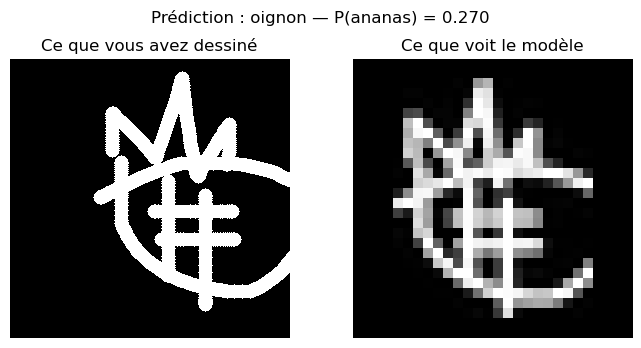

In [31]:
# 先完成上面的训练，再打开画板。
# 把 False 改成 True，然后运行本单元格。
OPEN_DRAWING_WINDOW = True

if OPEN_DRAWING_WINDOW:
    %gui qt5
    pad = show_draw(
        size=280, brush=7,
        classify_callback=classify_my_bitmap,
        title=f"QuickDraw — {class_names[0]} / {class_names[1]}",
    )
else:
    print("Pour ouvrir le canevas : mettre OPEN_DRAWING_WINDOW = True.")

### Variante : charger un dessin PNG

Si le canevas interactif ne fonctionne pas :

1. dessinez l'objet sur un fond blanc ou noir ;
2. enregistrez-le au format PNG dans le dossier du notebook ;
3. chargez le fichier avec `load_png_as_bitmap` ;
4. envoyez le tableau obtenu à `classify_my_bitmap`.

`load_png_as_bitmap` **ne recentre pas** l'image : elle se contente de
la lire et de mettre les traits en blanc sur fond noir. Le recentrage est
effectué une seule fois, dans `prepare_for_model`, au moment de la
classification.


In [29]:
# Exemple avec une image externe :
# my_img = load_png_as_bitmap("mon_dessin.png")
# classify_my_bitmap(my_img)

### 6.1 Bilan

Revenez à votre réponse de la Question préambule section 1,
après avoir comparé avec les autres groupes vos accuracies et types d'erreurs. 
**Question**  Quel couple semble le mieux séparé par un modèle linéaire ?


**手绘实验记录（需要你亲自完成）**：代码已补齐，但不能替你编造亲手画图的结果。
打开画板，至少画下面五类例子，把预测和概率记录下来；也可以保存 PNG 后调用 `classify_my_bitmap`。

| 绘图类型 | 目标类别 | 预测类别 | P(ananas) | 观察与分析 |
|---|---|---|---|---|
| 自然的 oignon | oignon | 待实测 | 待实测 | 待实测 |
| 自然的 ananas | ananas | 待实测 | 待实测 | 待实测 |
| 极简图 | 自定 | 待实测 | 待实测 | 待实测 |
| 模糊图 | 自定 | 待实测 | 待实测 | 待实测 |
| 试图欺骗模型的图 | 自定 | 待实测 | 待实测 | 待实测 |

本项目目前只测了 oignon–ananas，不能据此判断三个类别对中哪个最好分。
需要用相同流程测试其他类别对或取得其他组的实际结果后再比较。

In [30]:
# 完成手绘后，将每个 PNG 保存到 notebook 所在目录，
# 再取消下面对应行的注释，就能显示预测和实际输入图像。
# my_img = load_png_as_bitmap("mon_dessin.png")
# classify_my_bitmap(my_img)

print(f"Accuracy du modele lineaire sur ce test : {accuracy:.3f}")
print("Un seul couple a ete teste : on ne peut pas classer les trois couples.")

Accuracy du modele lineaire sur ce test : 0.833
Un seul couple a ete teste : on ne peut pas classer les trois couples.
